# 04: Model comparison

Milestone 3. Learned models are tuned and compared against the Milestone 2 baselines on the same
rows, features, folds and metrics, all from `src/chess_blunder/modelling.py`.

The rules carried over from `03_preprocessing_baseline.ipynb`:

- Every setting is chosen by **mean PR-AUC over the five grouped folds on the training games**.
- The test set (the most recent 20% of games) is not used to choose anything. It is scored once,
  for the chosen models only, later in this notebook.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / 'src'))

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

from chess_blunder import config, modelling

pd.set_option('display.width', 120)
FIG_DIR = config.REPORTS_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

positions = pd.read_parquet(config.PROCESSED_DIR / 'positions.parquet')

## 1. Same rows, same split, same folds

Rebuilt with the Milestone 2 functions and checked again, so this notebook stands on its own.

In [2]:
table = modelling.modelling_table(positions)
is_test = modelling.time_split(table)
train, test = table[~is_test].reset_index(drop=True), table[is_test].reset_index(drop=True)
folds = modelling.cv_folds(train)

assert not set(train.game_id) & set(test.game_id), 'a game is on both sides of the split'
assert train.end_time.max() < test.end_time.min(), 'test games are not all later than training games'
for fit_idx, val_idx in folds:
    assert not set(train.game_id.iloc[fit_idx]) & set(train.game_id.iloc[val_idx]), 'game split across folds'

print(f'train: {len(train):,} moves in {train.game_id.nunique():,} games, blunder rate {train[modelling.TARGET].mean():.2%}')
print(f'test : {len(test):,} moves in {test.game_id.nunique():,} games (not used until it is scored once, at the end)')

train: 102,880 moves in 3,206 games, blunder rate 9.39%
test : 27,168 moves in 802 games (not used until it is scored once, at the end)


## 2. Baselines

Recomputed on the same folds rather than read from `baselines_cv.csv`, so their out-of-fold
predictions are available for the plots later.

In [3]:
cv_scores, oof = {}, {}
for name, model in {'base rate': modelling.BaseRate(), 'stage x complexity': modelling.StageComplexityRate()}.items():
    cv_scores[name], oof[name] = modelling.out_of_fold(model, train, folds)

pd.DataFrame({name: s.drop(columns='base_rate').mean() for name, s in cv_scores.items()}).T.round(4)

,pr_auc,roc_auc,brier,train_pr_auc
base rate,0.0939,0.5000,0.0851,0.0939
stage x complexity,0.1320,0.6383,0.0833,0.1324


## 3. Logistic regression

The simplest learned model: a weighted sum of the features passed through a sigmoid. Three choices:

- **Splines on `cp_before` and `win_before`.** A linear model can only say "more of this feature,
  more (or less) risk". The table below shows the engine evaluation does not behave like that.

In [4]:
bands = pd.cut(train.win_before, np.arange(0, 101, 10))
train.groupby(bands, observed=True)[modelling.TARGET].agg(['mean', 'size']).rename(
    columns={'mean': 'blunder rate', 'size': 'moves'}).round(3)

,blunder rate,moves
win_before,,
"(0, 10]",0.006,18887
"(10, 20]",0.017,6516
"(20, 30]",0.140,3386
"(30, 40]",0.227,4106
"(40, 50]",0.128,16128
"(50, 60]",0.073,18129
"(60, 70]",0.180,5529
"(70, 80]",0.263,3942
"(80, 90]",0.207,6553


Risk is under 2% when I am clearly losing (`win_before` below 20): a 15-point drop in winning
chances is almost impossible from there, so this is partly how the label works rather than how I
play. It is 6.5% when I am clearly winning (above 90). It peaks at 20–26% where one side is ahead
but the game is not decided (30–40 and 70–80), and dips at dead level (40–60). Two peaks and a dip
cannot be fitted by one weight, so both engine columns are expanded into cubic splines with knots
at quantiles.

- **No class weights.** Blunders are ~9% of moves. Reweighting them would make the model rank moves
  much the same way but push every predicted risk upwards, which spoils the Brier score and the
  reliability plot. PR-AUC measures ranking, so it loses nothing.
- **Tuning the regularisation strength `C`** over 0.01, 0.1, 1 and 10. Smaller `C` shrinks the
  weights towards zero; larger `C` lets the model fit the training folds more closely.

In [5]:
lr = modelling.tune(modelling.logistic_regression, {'C': [0.01, 0.1, 1, 10]}, train, folds)
cv_scores['logistic regression'] = lr.results
oof['logistic regression'] = lr.oof

assert len(lr.oof) == len(train), 'out-of-fold predictions must cover every training row'
print('chosen:', lr.best_params)
lr.results.round(4)

chosen: {'C': 10}


,C,mean pr_auc,std pr_auc,mean roc_auc,std roc_auc,mean brier,std brier,mean train_pr_auc,std train_pr_auc
0,0.01,0.2294,0.0109,0.7673,0.0069,0.0785,0.0015,0.2295,0.0029
1,0.10,0.2348,0.0106,0.7801,0.0079,0.0778,0.0014,0.2352,0.0031
2,1.00,0.2350,0.0104,0.7825,0.0078,0.0777,0.0015,0.2353,0.0032
3,10.00,0.2352,0.0103,0.7827,0.0079,0.0777,0.0015,0.2355,0.0033


`C` hardly matters. From 0.1 to 10, mean PR-AUC moves by 0.0004, about a twenty-fifth of the
fold std (0.010). With ~100,000 training moves and 28 columns after the splines and one-hot
encoding, there is little to overfit, so regularisation has almost nothing to do. `C = 10` wins on
the rule and sits at the edge of the grid, but extending the grid would only chase noise. Only
`C = 0.01` is visibly worse: it shrinks the weights too far.

### Do the splines earn their place?

The same model at the chosen `C`, with the engine columns left linear. If the splines matter, this
should score clearly lower.

In [6]:
linear = make_pipeline(modelling.make_preprocessor(), LogisticRegression(C=lr.best_params['C'], max_iter=1000))
linear_scores = modelling.cross_validate(linear, train, folds).drop(columns='base_rate')
spline_row = lr.results.loc[lr.results.C == lr.best_params['C']].iloc[0]

pd.DataFrame({
    'with splines': {m: spline_row[f'mean {m}'] for m in ('pr_auc', 'roc_auc', 'brier')},
    'linear only': linear_scores[['pr_auc', 'roc_auc', 'brier']].mean(),
}).T.round(4)

,pr_auc,roc_auc,brier
with splines,0.2352,0.7827,0.0777
linear only,0.1561,0.6726,0.0828


They do. Without them, PR-AUC falls from 0.235 to 0.156, only a little above the stage ×
complexity table (0.132). Most of what logistic regression adds over the baseline comes from
reading the shape of the engine evaluation. That also means part of the lift is the label effect
above: decided positions rarely produce blunders, and the model learns that quickly. The error
analysis later in this notebook slices by `win_before` band to show how much is left beyond it.

## 4. Gradient boosting

Gradient boosting builds lots of small decision trees one after another. Each new tree focuses on
the mistakes the trees before it made, and the final prediction adds them all up. Trees split on raw
values, so unlike logistic regression it doesn't need splines or scaling; it uses the same
preprocessor with those switched off, so it sees the same columns.

Early stopping is turned off because its internal check picks random moves, not whole games, so it
would be checking itself on games it has partly seen. Instead, the number of trees is part of the
grid: 100 or 300 trees, learning rate 0.05 or 0.1, and a minimum of 20 or 200 moves per leaf, so 8
settings. No class weights, for the same reason as logistic regression.

In [7]:
gb_grid = {'max_iter': [100, 300], 'learning_rate': [0.05, 0.1], 'min_samples_leaf': [20, 200]}
gb = modelling.tune(modelling.gradient_boosting, gb_grid, train, folds)
cv_scores['gradient boosting'] = gb.results
oof['gradient boosting'] = gb.oof

print('chosen:', gb.best_params)
gb.results.sort_values('mean pr_auc', ascending=False).round(4)

chosen: {'learning_rate': 0.05, 'max_iter': 100, 'min_samples_leaf': 20}


,learning_rate,max_iter,min_samples_leaf,mean pr_auc,std pr_auc,mean roc_auc,std roc_auc,mean brier,std brier,mean train_pr_auc,std train_pr_auc
0,0.05,100,20,0.2689,0.0151,0.8181,0.0045,0.0751,0.0013,0.3355,0.0034
1,0.05,100,200,0.2662,0.0124,0.8173,0.0051,0.0752,0.0013,0.3182,0.0036
2,0.05,300,20,0.2630,0.0119,0.8166,0.0056,0.0754,0.0014,0.4546,0.0061
4,0.10,100,20,0.2627,0.0117,0.8164,0.0048,0.0753,0.0013,0.3927,0.0044
5,0.10,100,200,0.2625,0.0092,0.8165,0.0049,0.0753,0.0014,0.3522,0.0032
3,0.05,300,200,0.2617,0.0130,0.8161,0.0060,0.0754,0.0013,0.3962,0.0046
7,0.10,300,200,0.2565,0.0107,0.8131,0.0054,0.0759,0.0013,0.4916,0.0039
6,0.10,300,20,0.2546,0.0113,0.8132,0.0062,0.0761,0.0014,0.5811,0.0059


The best setting is 100 trees, learning rate 0.05 and minimum leaf 20, at 0.269 PR-AUC. It's at the
edge of the grid (fewest trees, slower learning rate), but it only beats the next best by 0.003, well
under the fold std of 0.015, so by the rule I set I don't widen the grid. The pattern is consistent
though: the settings that learn less score better held out. That's what the next table looks at.

### Is it overfitting?

Each setting is scored on the moves it trained on as well as the held-out fold. If the training
score is much higher than the held-out score, the model is memorising training games rather than
learning patterns that carry over.

In [8]:
pd.set_option('display.max_colwidth', None)

def label(results: pd.DataFrame, keys) -> pd.Series:
    """A readable name for each setting, such as 'max_iter=300, learning_rate=0.1'."""
    return results[list(keys)].apply(
        lambda r: ', '.join(f'{k}={r[k]:g}' if pd.notna(r[k]) else f'{k}=None' for k in keys), axis=1)

fit_gap = pd.concat([
    lr.results.assign(model='logistic regression', setting=label(lr.results, ['C'])),
    gb.results.assign(model='gradient boosting', setting=label(gb.results, gb_grid)),
]).set_index(['model', 'setting'])[['mean train_pr_auc', 'mean pr_auc']]
fit_gap.columns = ['train', 'held out']
fit_gap['gap'] = fit_gap['train'] - fit_gap['held out']
fit_gap.round(4)

train  held out     gap
model               setting                                                                         
logistic regression C=0.01                                                  0.2295    0.2294  0.0001
                    C=0.1                                                   0.2352    0.2348  0.0003
                    C=1                                                     0.2353    0.2350  0.0003
                    C=10                                                    0.2355    0.2352  0.0003
gradient boosting   max_iter=100, learning_rate=0.05, min_samples_leaf=20   0.3355    0.2689  0.0666
                    max_iter=100, learning_rate=0.05, min_samples_leaf=200  0.3182    0.2662  0.0520
                    max_iter=300, learning_rate=0.05, min_samples_leaf=20   0.4546    0.2630  0.1915
                    max_iter=300, learning_rate=0.05, min_samples_leaf=200  0.3962    0.2617  0.1345
                    max_iter=100, learning_rate=0.1, min_samples_leaf=20    0.3927    0.2627  0.1300
                    max_iter=100, learning_rate=0.1, min_samples_leaf=200   0.3522    0.2625  0.0897
                    max_iter=300, learning_rate=0.1, min_samples_leaf=20    0.5811    0.2546  0.3265
                    max_iter=300, learning_rate=0.1, min_samples_leaf=200   0.4916    0.2565  0.2351

Logistic regression barely overfits: its training and held-out scores differ by 0.0003. Gradient
boosting overfits much more, and the more freedom a setting gives it (more trees, a faster learning
rate), the bigger the gap and the worse it does on held-out games. The worst setting scores 0.58 on
training but only 0.25 held out. The chosen setting still has a gap of 0.07, but it's the best on the
games that matter.

### Does it beat logistic regression?

Both models were scored on the same five folds, so I compare them fold by fold. Some folds are
harder than others for both models, so comparing within each fold cancels that out. The rule I set:
gradient boosting only counts as better if it wins on all five folds.

In [9]:
paired = modelling.fold_differences(lr.fold_scores, gb.fold_scores).rename(
    columns={'a': 'logistic regression', 'b': 'gradient boosting', 'b - a': 'difference'})
print(f"gradient boosting better on {(paired['difference'] > 0).sum()} of {len(paired)} folds")
paired.round(4)

gradient boosting better on 5 of 5 folds


,logistic regression,gradient boosting,difference
fold,,,
0,0.2261,0.2610,0.0350
1,0.2500,0.2927,0.0427
2,0.2417,0.2707,0.0290
3,0.2310,0.2679,0.0369
4,0.2274,0.2523,0.0248


Gradient boosting wins on all five folds, by between 0.025 and 0.043 PR-AUC, so it is the best model
so far. It's less interpretable than logistic regression, and permutation importance later on will
help show what it relies on.

## 5. Random forest

A random forest builds lots of full decision trees independently, each on a random sample of the
moves and of the features, and averages their votes. Averaging cancels out each tree's individual
mistakes. It uses the same preprocessor as gradient boosting. The number of trees is fixed at 300,
because more trees in a forest just averages away more noise, it doesn't overfit. The grid tries a
maximum depth of 10 or no limit, and a minimum of 20 or 100 moves per leaf, so 4 settings. Each
split looks at the default random subset of features (about 4 of 16), and there are no class
weights.

In [10]:
import time

rf_grid = {'max_depth': [10, None], 'min_samples_leaf': [20, 100]}
start = time.perf_counter()
rf = modelling.tune(modelling.random_forest, rf_grid, train, folds)
print(f'tuning took {(time.perf_counter() - start) / 60:.1f} minutes')
cv_scores['random forest'] = rf.results
oof['random forest'] = rf.oof

print('chosen:', rf.best_params)
rf.results.sort_values('mean pr_auc', ascending=False).round(4)

tuning took 0.8 minutes
chosen: {'max_depth': None, 'min_samples_leaf': 20}


,max_depth,min_samples_leaf,mean pr_auc,std pr_auc,mean roc_auc,std roc_auc,mean brier,std brier,mean train_pr_auc,std train_pr_auc
2,NaN,20,0.2664,0.0121,0.8173,0.0056,0.0752,0.0014,0.5552,0.0061
0,10.0,20,0.2648,0.0118,0.8138,0.0054,0.0757,0.0015,0.3333,0.0026
3,NaN,100,0.2605,0.0117,0.8138,0.0053,0.0756,0.0014,0.3273,0.0033
1,10.0,100,0.2575,0.0127,0.8108,0.0054,0.0760,0.0014,0.2912,0.0035


The best setting is no depth limit with a minimum leaf of 20, at 0.266 PR-AUC. It's at the edge of
the grid, but it only beats the next best by 0.002, well under the fold std of 0.012, so I don't
widen the grid. Tuning took under a minute, so there was no need to cut the number of trees.

### Is it overfitting?

Same check as gradient boosting: training score against held-out score for each setting. A
forest's training score is expected to look high, because deep trees nearly memorise the moves they
were trained on, so the held-out score is the one that counts.

In [11]:
rf_gap = rf.results.assign(setting=label(rf.results, rf_grid)).set_index('setting')[['mean train_pr_auc', 'mean pr_auc']]
rf_gap.columns = ['train', 'held out']
rf_gap['gap'] = rf_gap['train'] - rf_gap['held out']
rf_gap.round(4)

,train,held out,gap
setting,,,
"max_depth=10, min_samples_leaf=20",0.3333,0.2648,0.0685
"max_depth=10, min_samples_leaf=100",0.2912,0.2575,0.0336
"max_depth=None, min_samples_leaf=20",0.5552,0.2664,0.2888
"max_depth=None, min_samples_leaf=100",0.3273,0.2605,0.0668


The deepest trees (no depth limit, leaf 20) have the biggest gap, 0.56 on training against 0.27 held
out, but they're still the best on held-out games. Each tree overfits, but averaging 300 of them
cancels most of that out, which is the whole point of a forest. Gradient boosting was different:
its overfit settings did worse held out.

### Does it beat gradient boosting?

The forest is compared fold by fold against gradient boosting, the best model so far. It only
replaces it if it wins on all five folds; if the result is mixed, gradient boosting stays. It's
also compared against logistic regression for completeness.

In [12]:
for rival, scores in [('gradient boosting', gb.fold_scores), ('logistic regression', lr.fold_scores)]:
    paired = modelling.fold_differences(scores, rf.fold_scores).rename(
        columns={'a': rival, 'b': 'random forest', 'b - a': 'difference'})
    print(f"random forest better than {rival} on {(paired['difference'] > 0).sum()} of {len(paired)} folds")
    display(paired.round(4))

random forest better than gradient boosting on 1 of 5 folds


,gradient boosting,random forest,difference
fold,,,
0,0.2610,0.2590,-0.0021
1,0.2927,0.2866,-0.0061
2,0.2707,0.2655,-0.0052
3,0.2679,0.2654,-0.0025
4,0.2523,0.2554,0.0032


random forest better than logistic regression on 5 of 5 folds


,logistic regression,random forest,difference
fold,,,
0,0.2261,0.2590,0.0329
1,0.2500,0.2866,0.0367
2,0.2417,0.2655,0.0238
3,0.2310,0.2654,0.0344
4,0.2274,0.2554,0.0280


The forest beats gradient boosting on only one of five folds, and every difference is under 0.007,
so the two are effectively tied and gradient boosting stays the best model. The forest does beat
logistic regression on all five folds. Both tree models land at about 0.27, which suggests that's
about the limit of what these features can tell us, whichever tree model is used.

## Results so far

Cross-validated on the training games, mean ± std over five folds. Each learned model is shown at
its chosen setting.

In [13]:
def summarise(scores: pd.DataFrame) -> dict:
    """Mean ± std of each metric: from per-fold scores, or from a tuning row already aggregated."""
    if 'mean pr_auc' in scores:
        row = scores.loc[scores['mean pr_auc'].idxmax()]
        return {m: f"{row[f'mean {m}']:.3f} ± {row[f'std {m}']:.3f}" for m in ('pr_auc', 'roc_auc', 'brier')}
    return {m: f'{scores[m].mean():.3f} ± {scores[m].std():.3f}' for m in ('pr_auc', 'roc_auc', 'brier')}

comparison = pd.DataFrame({name: summarise(s) for name, s in cv_scores.items()}).T
comparison.to_csv(config.REPORTS_DIR / 'model_comparison_cv.csv')
comparison

,pr_auc,roc_auc,brier
base rate,0.094 ± 0.002,0.500 ± 0.000,0.085 ± 0.002
stage x complexity,0.132 ± 0.003,0.638 ± 0.004,0.083 ± 0.002
logistic regression,0.235 ± 0.010,0.783 ± 0.008,0.078 ± 0.001
gradient boosting,0.269 ± 0.015,0.818 ± 0.004,0.075 ± 0.001
random forest,0.266 ± 0.012,0.817 ± 0.006,0.075 ± 0.001


All three learned models clearly beat the stage × complexity table. Gradient boosting is the best:
0.269 PR-AUC against 0.266 for the random forest and 0.235 for logistic regression, with the lowest
Brier score (0.075). The forest is effectively tied with it but wins on only one fold, so gradient
boosting stays the chosen model. Next: plots of the out-of-fold predictions, then the test set,
scored once.

## 6. Plots

### Precision-recall curve

For each of the models, I've sorted moves from highest to lowest predicted risk, so going left to
right ends up flagging more of them. Recall is how many of the actual blunders get caught, and
precision is how many flagged moves were actually blunders. The dashed line is the base rate, which
is how well randomly guessing would do. The PR-AUC in the legend uses all 5 folds together, so it's
a little bit different from the table.

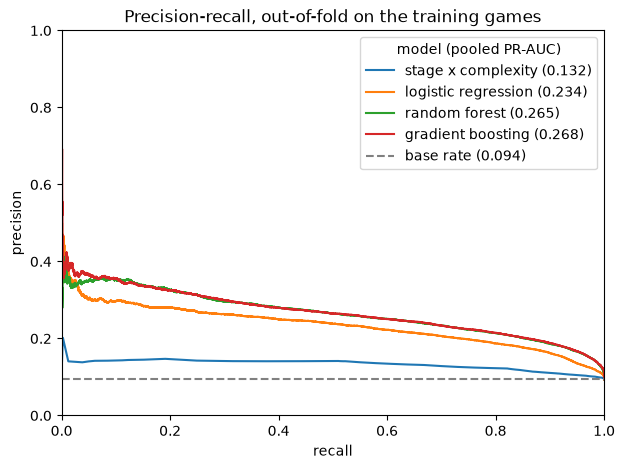

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve

y = train[modelling.TARGET]
COLOURS = {'stage x complexity': 'tab:blue', 'logistic regression': 'tab:orange',
           'random forest': 'tab:green', 'gradient boosting': 'tab:red'}  # same model, same colour in both plots

fig, ax = plt.subplots(figsize=(7, 5))
for name in ['stage x complexity', 'logistic regression', 'random forest', 'gradient boosting']:
    precision, recall, _ = precision_recall_curve(y, oof[name])
    ax.plot(recall, precision, color=COLOURS[name], label=f'{name} ({average_precision_score(y, oof[name]):.3f})')
ax.axhline(y.mean(), color='grey', linestyle='--', label=f'base rate ({y.mean():.3f})')
ax.set(xlabel='recall', ylabel='precision', xlim=(0, 1), ylim=(0, 1),
       title='Precision-recall, out-of-fold on the training games')
ax.legend(title='model (pooled PR-AUC)')
fig.savefig(FIG_DIR / '04_pr_curve.png', dpi=150, bbox_inches='tight')

As you can see from the graph, gradient boosting and the random forest are nearly on top of each
other, which fits with them tying fold by fold. At 50% recall, about 27% of gradient boosting's
flagged moves are blunders, compared to 24% for logistic regression, 14% for the stage × complexity
table and only 9% for random guessing. The table's line is almost flat because it only has 18
cells, so every move in a cell gets the same risk. There's also a spike on the far left, which is
only a handful of moves, so I'm going to ignore it.

### Reliability

PR-AUC only checks whether the model ranks moves in the correct order. This plot checks whether
the risk numbers themselves are right. I've split moves into 10 equal-sized groups by predicted
risk, and for each group, the average predicted risk is plotted against how many were actually
blunders. If the predictions are right, the points sit on the dashed line.

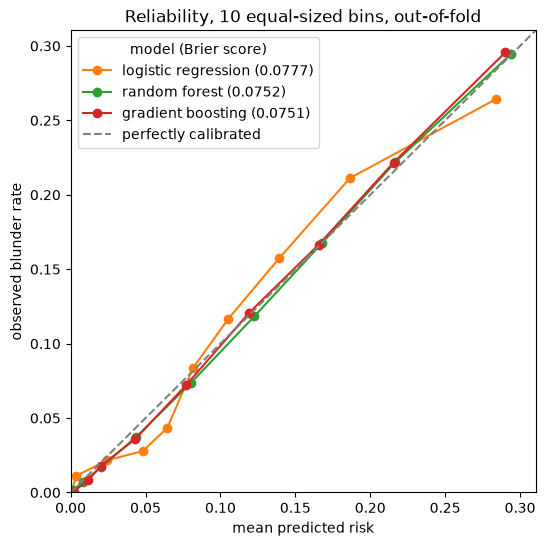

In [15]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(6, 6))
for name in ['logistic regression', 'random forest', 'gradient boosting']:
    observed, predicted = calibration_curve(y, oof[name], n_bins=10, strategy='quantile')
    ax.plot(predicted, observed, marker='o', color=COLOURS[name], label=f'{name} ({brier_score_loss(y, oof[name]):.4f})')
top = max(ax.get_xlim()[1], ax.get_ylim()[1])
ax.plot([0, top], [0, top], color='grey', linestyle='--', label='perfectly calibrated')
ax.set(xlabel='mean predicted risk', ylabel='observed blunder rate', xlim=(0, top), ylim=(0, top),
       title='Reliability, 10 equal-sized bins, out-of-fold')
ax.legend(title='model (Brier score)')
fig.savefig(FIG_DIR / '04_reliability.png', dpi=150, bbox_inches='tight')

Both tree models sit right on the diagonal, so their predicted risk matches what actually happens.
This backs up not using class weights. Logistic regression is a bit off: it overestimates around 5%
and underestimates between 10% and 19%. That's also why its Brier score is a little worse (0.078
versus 0.075).

## 7. Test set

The test set is the most recent 20% of my games (802 games, 27,168 moves), and nothing so far has
touched it. Each model is retrained on all the training games at the setting cross-validation
picked, then scored once on the test games. Gradient boosting was chosen as the final model before
this was run.

### Freeze rule

After this cell runs, I don't change any model, setting or feature based on the test results. If I
find a bug later, I fix it and report both the old and new numbers and why. The test numbers are
saved separately and aren't used to rank models.

In [16]:
CHOSEN = 'gradient boosting'  # fixed by cross-validation in sections 4 and 5, before the test set is scored

final_models = {
    'base rate': modelling.BaseRate(),
    'stage x complexity': modelling.StageComplexityRate(),
    'logistic regression': modelling.logistic_regression(**lr.best_params),
    'random forest': modelling.random_forest(**rf.best_params),
    'gradient boosting': modelling.gradient_boosting(**gb.best_params),
}
test_risk = {}
for name, model in final_models.items():
    model.fit(train, train[modelling.TARGET])
    test_risk[name] = model.predict_proba(test)[:, 1]

y_test = test[modelling.TARGET]
cv_pr_auc = {name: s['mean pr_auc'].max() if 'mean pr_auc' in s else s['pr_auc'].mean() for name, s in cv_scores.items()}
test_table = pd.DataFrame({name: modelling.score(y_test, risk) for name, risk in test_risk.items()}).T.drop(columns='base_rate')
test_table['lift'] = test_table['pr_auc'] / y_test.mean()
test_table['cv lift'] = pd.Series(cv_pr_auc) / train[modelling.TARGET].mean()
test_table.to_csv(config.REPORTS_DIR / 'model_comparison_test.csv')

print(f'test base rate {y_test.mean():.2%} (training {train[modelling.TARGET].mean():.2%}); chosen model: {CHOSEN}')
test_table.round(4)

test base rate 8.37% (training 9.39%); chosen model: gradient boosting


,pr_auc,roc_auc,brier,lift,cv lift
base rate,0.0837,0.5000,0.0768,1.0000,1.0002
stage x complexity,0.1232,0.6432,0.0752,1.4721,1.4053
logistic regression,0.2070,0.7687,0.0712,2.4736,2.5053
random forest,0.2256,0.7991,0.0699,2.6969,2.8370
gradient boosting,0.2373,0.8043,0.0693,2.8368,2.8640


Blunders are rarer in the test games (8.4% vs 9.4%), so every PR-AUC is lower than in
cross-validation. Lift (PR-AUC divided by the base rate) takes that out. Gradient boosting's lift is
2.84 on test against 2.86 in cross-validation, so it holds up on newer games. The ranking is the
same as in cross-validation. The Brier scores are lower on test only because blunders are rarer,
not because the models got better.

### How sure are these numbers?

There's only one test set, so each number has no spread. To get one, I resample the 802 test games
with replacement 1,000 times and rescore each time. Whole games are resampled, not single moves,
for the same reason the folds are grouped by game. The middle 95% of the results gives the
interval.

In [17]:
boot = modelling.bootstrap_pr_auc(y_test, test_risk, test.game_id)
boot['gradient boosting - random forest'] = boot['gradient boosting'] - boot['random forest']
boot['gradient boosting - logistic regression'] = boot['gradient boosting'] - boot['logistic regression']

boot.quantile([0.025, 0.5, 0.975]).T.rename(columns={0.025: '2.5%', 0.5: 'median', 0.975: '97.5%'}).round(4)

,2.5%,median,97.5%
base rate,0.0799,0.0836,0.0876
stage x complexity,0.1149,0.1232,0.1311
logistic regression,0.1931,0.2075,0.2240
random forest,0.2123,0.2270,0.2419
gradient boosting,0.2220,0.2382,0.2546
gradient boosting - random forest,0.0050,0.0115,0.0185
gradient boosting - logistic regression,0.0188,0.0306,0.0444


Gradient boosting's test PR-AUC is between 0.222 and 0.255. In cross-validation it was tied with
the random forest, but on the test games it's ahead by 0.005 to 0.019, and that interval doesn't
include zero. The forest dropped more on newer games (lift 2.84 → 2.70). Gradient boosting is also
clearly ahead of logistic regression (0.019 to 0.044). So the test set backs up choosing gradient
boosting.

## 8. Which features does the model use?

This checks which features gradient boosting actually relies on. For each fold, I shuffle a group of
features in the held-out games and see how much PR-AUC drops. Features that carry the same
information are shuffled together (for example `cp_before` and `win_before` are both the engine's
evaluation), because if I shuffled just one, the model would still read it from the other. It all
runs on the training folds, so the test set isn't touched again.

,mean,std,columns
engine evaluation,0.1570,0.0134,"cp_before, win_before"
game progress,0.0643,0.0134,"ply, game_stage"
material,0.0498,0.0072,"pieces_white, pieces_black, material_diff"
legal moves,0.0308,0.0070,legal_moves
rating,0.0091,0.0039,my_rating_pre
clock,0.0061,0.0023,seconds_before
colour,0.0000,0.0001,mover
time control,-0.0001,0.0001,"tc_base, tc_increment"


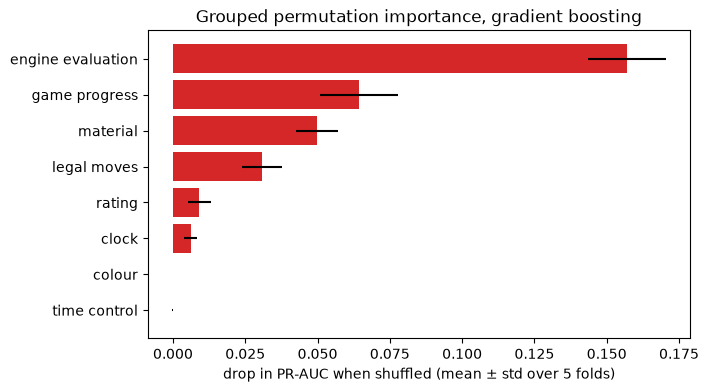

In [18]:
importance = modelling.grouped_permutation_importance(modelling.gradient_boosting(**gb.best_params), train, folds)
summary = importance.agg(['mean', 'std']).T.sort_values('mean')

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(summary.index, summary['mean'], xerr=summary['std'], color=COLOURS['gradient boosting'])
ax.set(xlabel='drop in PR-AUC when shuffled (mean ± std over 5 folds)',
       title='Grouped permutation importance, gradient boosting')
fig.savefig(FIG_DIR / '04_importance.png', dpi=150, bbox_inches='tight')

columns = pd.Series({group: ', '.join(cols) for group, cols in modelling.FEATURE_GROUPS.items()}, name='columns')
summary[::-1].join(columns).round(4)

The engine evaluation is by far the most important. Shuffling it drops PR-AUC by 0.157, which takes
the model from 0.269 down to about 0.11, close to the stage × complexity table. Game progress (ply
and stage), material and the number of legal moves come next. My rating and the clock barely
matter, and colour and time control add nothing. So the model mostly works out how close the game
is and how complicated the position is. One caveat: this shows what the model uses, not what causes
blunders.

## 9. Where does the model do badly?

The overall PR-AUC hides where the model does well or badly, so I split gradient boosting's
out-of-fold predictions by game stage, number of legal moves, time left on my clock and `win_before`
band. PR-AUC can't be compared between slices with different blunder rates, so each slice also gets
its base rate and lift. The last column flags the riskiest 10% of all moves (one threshold for
everything) and shows what share of each slice's blunders that catches.

In [19]:
slices = {
    'game stage': train.game_stage,
    'legal moves': pd.cut(train.legal_moves, modelling.LEGAL_MOVE_BINS),
    'seconds left on my clock': pd.cut(train.seconds_before, [0, 30, 60, 120, 300, 600, np.inf]),
    'win_before band': pd.cut(train.win_before, [0, 20, 40, 60, 80, 100]),
}
for title, groups in slices.items():
    print(title)
    display(modelling.error_slices(y, oof['gradient boosting'], groups).round(3))

game stage


,moves,base rate,pr_auc,recall in top 10%,lift
endgame,12025,0.045,0.176,0.043,3.921
middlegame,59386,0.110,0.280,0.387,2.540
opening,31469,0.082,0.247,0.190,3.006


legal moves


,moves,base rate,pr_auc,recall in top 10%,lift
"(0.0, 10.0]",13422,0.046,0.187,0.070,4.110
"(10.0, 20.0]",11536,0.037,0.198,0.062,5.420
"(20.0, 30.0]",27997,0.077,0.248,0.180,3.212
"(30.0, 40.0]",36216,0.124,0.269,0.350,2.169
"(40.0, 50.0]",12587,0.145,0.303,0.506,2.087
"(50.0, inf]",1122,0.127,0.334,0.606,2.636


seconds left on my clock


,moves,base rate,pr_auc,recall in top 10%,lift
"(0.0, 30.0]",1555,0.070,0.211,0.174,3.007
"(30.0, 60.0]",1720,0.065,0.270,0.232,4.148
"(60.0, 120.0]",2203,0.059,0.188,0.145,3.154
"(120.0, 300.0]",14838,0.070,0.272,0.321,3.877
"(300.0, 600.0]",78503,0.100,0.268,0.315,2.669
"(600.0, inf]",4061,0.096,0.296,0.417,3.079


win_before band


,moves,base rate,pr_auc,recall in top 10%,lift
"(0, 20]",25403,0.009,0.061,0.009,7.113
"(20, 40]",7492,0.188,0.273,0.374,1.456
"(40, 60]",34257,0.099,0.259,0.261,2.625
"(60, 80]",9471,0.215,0.322,0.485,1.501
"(80, 100]",26257,0.100,0.236,0.247,2.364


Two weak spots stand out.

- **Endgames and simple positions.** The model catches only 4% of endgame blunders in its top 10%,
  and 6–7% for positions with 20 or fewer legal moves. The lift there is high, but only because the
  base rate is low: it ranks endgame moves fairly well against each other, but never rates them as
  risky as middlegame moves, so in practice it would almost never warn me in an endgame.
- **Unbalanced but undecided positions.** Where `win_before` is 20–40 or 60–80, about 1 in 5 moves is
  a blunder, but the lift is only about 1.5. The model knows these positions are dangerous, but it
  can't tell which move in them will be the blunder.

Where I'm clearly losing (`win_before` under 20), blunders are under 1% because of how the label
works (a 15-point drop is almost impossible from there), so the low PR-AUC there doesn't matter
much. The clock slices are mixed and small: only about 3% of moves are made with under a minute
left, so time trouble is rare in these games.

## 10. Thinking time and time pressure

The secondary question from the proposal is whether thinking time predicts blunders.
`seconds_spent` can't be a feature, because it's only known after the move is made (it's on the
leakage list), so this part is descriptive only. First, the blunder rate by how long I spent on the
move. Then the same thing split into thirds by the model's predicted risk, so hard positions are
compared with hard positions and easy with easy.

In [20]:
thinking = pd.cut(train.seconds_spent, [0, 2, 5, 10, 20, np.inf], labels=['under 2s', '2-5s', '5-10s', '10-20s', 'over 20s'])
risk_tier = pd.qcut(oof['gradient boosting'], 3, labels=['low risk', 'medium risk', 'high risk'])

display(train.groupby(thinking, observed=True)[modelling.TARGET].agg(['mean', 'size']).rename(
    columns={'mean': 'blunder rate', 'size': 'moves'}).round(3))
by_tier = train.groupby([risk_tier, thinking], observed=True)[modelling.TARGET]
print('blunder rate by risk tier (rows) and thinking time (columns); smallest cell:', by_tier.size().min(), 'moves')
by_tier.mean().unstack().round(3)

seconds_spent,under 2s,2-5s,5-10s,10-20s,over 20s
blunder rate,0.041,0.07,0.104,0.136,0.156
moves,13170.000,30207.00,26442.000,19321.000,10534.000


blunder rate by risk tier (rows) and thinking time (columns); smallest cell: 2605 moves


seconds_spent,under 2s,2-5s,5-10s,10-20s,over 20s
low risk,0.002,0.003,0.005,0.005,0.007
medium risk,0.038,0.050,0.063,0.074,0.081
high risk,0.129,0.173,0.218,0.258,0.288


The blunder rate goes up the longer I think: 4% for moves under 2 seconds, up to about 16% for
moves over 20 seconds. That still holds inside each risk tier (in the high-risk third, 13% under 2
seconds against 29% over 20 seconds). This is an association, not cause and effect. The likely
reading is that I think longer in positions that are hard in ways the features don't capture, not
that thinking makes me blunder. It definitely doesn't support "play faster".

### Does time pressure help the model?

`seconds_before` (time left on my clock) is a real feature, so I can check whether it helps: retrain
gradient boosting at the same setting without it and compare fold by fold.

In [21]:
no_clock = modelling.cross_validate(modelling.gradient_boosting(**gb.best_params, drop=('seconds_before',)), train, folds)
paired = modelling.fold_differences(gb.fold_scores, no_clock).rename(
    columns={'a': 'with clock', 'b': 'without clock', 'b - a': 'difference'})
print(f"without the clock: better on {(paired['difference'] > 0).sum()} of {len(paired)} folds, "
      f"mean difference {paired['difference'].mean():+.4f}")
paired.round(4)

without the clock: better on 2 of 5 folds, mean difference +0.0006


,with clock,without clock,difference
fold,,,
0,0.2610,0.2601,-0.0009
1,0.2927,0.2902,-0.0025
2,0.2707,0.2752,0.0045
3,0.2679,0.2663,-0.0016
4,0.2523,0.2557,0.0035


Dropping it makes no difference: the model without it is better on 2 folds and worse on 3, and the
mean changes by less than 0.001. That matches the permutation importance. Time left on the clock
doesn't help predict my blunders, probably because I'm rarely short of time in rapid games.